In [69]:
import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup
from matplotlib.patches import Patch
from urllib.robotparser import RobotFileParser

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

headers = {
    "User-Agent": "Mozilla/5.0 (Data Collection & Preparation - SIS1: Credit Affordability & Interest Rate Trends in Kazakhstan)"
}

In [70]:
indicators = {
    "FP.CPI.TOTL.ZG": "inflation",
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "SL.UEM.TOTL.ZS": "unemployment"
}

rows = []

In [71]:
for code, name in indicators.items():
    url = f"https://api.db.nomics.world/v22/series/WB/WDI/A-{code}-KAZ"

    response = requests.get(
        url,
        params={"observations": 1},
        headers=headers,
        timeout=60
    )

    response.raise_for_status()

    docs = response.json().get("series", {}).get("docs", [])

    if not docs:
        print("No data for", code)
        continue

    doc = docs[0]

    for year, value in zip(doc.get("period", []), doc.get("value", [])):
        rows.append({
            "year": int(year),
            "indicator": name,
            "value": pd.to_numeric(value, errors="coerce")
        })

In [72]:
raw_wb = pd.DataFrame(rows)

raw_wb = raw_wb[
    raw_wb["year"].between(2005, 2025)
].dropna(subset=["value"])

raw_wb = raw_wb.sort_values(
    ["indicator", "year"]
).reset_index(drop=True)

print(raw_wb.groupby("indicator")["year"].agg(["min", "max", "count"]))
raw_wb.head(10)

                 min   max  count
indicator                        
gdp_per_capita  2005  2023     19
inflation       2005  2023     19
unemployment    2005  2023     19


,year,indicator,value
0,2005,gdp_per_capita,3771.278957
1,2006,gdp_per_capita,5291.574004
2,2007,gdp_per_capita,6771.416620
3,2008,gdp_per_capita,8458.019475
4,2009,gdp_per_capita,7165.224778
5,2010,gdp_per_capita,9070.488253
6,2011,gdp_per_capita,11633.998584
7,2012,gdp_per_capita,12386.699265
8,2013,gdp_per_capita,13890.633969
9,2014,gdp_per_capita,12807.263045


In [73]:
bankchart_base = "https://bankchart.kz"
bankchart_url = bankchart_base + "/potrebitelskie_kredity/reytingi"
robots_url = bankchart_base + "/robots.txt"

robots_response = requests.get(robots_url, headers=headers, timeout=60)
print("robots.txt status:", robots_response.status_code)
print(robots_response.text[:1500])

robots.txt status: 200
User-agent: *
Disallow: /*?*
Disallow: /*filter/data$
Disallow: /company-links/
Host: https://bankchart.kz



In [74]:
rp = RobotFileParser(robots_url)
rp.read()

allowed = rp.can_fetch("*", bankchart_url)
print("Scraping allowed:", allowed)

assert allowed

Scraping allowed: True


In [75]:
response = requests.get(
    bankchart_url,
    headers=headers,
    timeout=60
)

response.raise_for_status()
response.encoding = "utf-8"

html = response.text

print("Status:", response.status_code)
print("Page size:", len(html))

Status: 200
Page size: 71817


In [76]:
soup = BeautifulSoup(html, "html.parser")

page_text = soup.get_text(" ", strip=True)

date_match = re.search(r"Дата:\s*(\d{2}\.\d{2}\.\d{4})", page_text)
page_date = date_match.group(1) if date_match else "Unknown"

print("Rating date on the page:", page_date)

Rating date on the page: 31.07.2026


In [77]:
bank_rows = []

for link in soup.find_all("a", href=True):
    if "/spravochniki/banki/id/" not in link["href"]:
        continue

    bank_name = link.get_text(" ", strip=True)

    if bank_name == "":
        continue

    block = link

    while block is not None and "реальная ставка" not in block.get_text(" ", strip=True):
        block = block.parent

    if block is None:
        continue

    text = block.get_text(" ", strip=True)

    if text.count("реальная ставка") != 1:
        print("Skipped, block has several rows:", bank_name)
        continue

    position = page_text.find(text)
    after_text = ""

    if position != -1:
        after_text = page_text[position + len(text): position + len(text) + 400]
        after_text = after_text.split("реальная ставка")[0]

    bank_rows.append({
        "bank": bank_name,
        "text": text,
        "after_text": after_text
    })

raw_banks = pd.DataFrame(bank_rows).drop_duplicates("bank")

print("Banks found:", len(raw_banks))
assert len(raw_banks) > 0

print(raw_banks["text"].iloc[0])

Banks found: 11
1 Home Credit Bank Кредит наличными 19,00 реальная ставка, % от 98 949,77 ежемесячный платёж 102 916,67


In [78]:
raw_banks["effective_rate"] = raw_banks["text"].str.extract(
    r"(\d+(?:[.,]\d+)?)\s*реальная ставка",
    expand=False
)

raw_banks["nominal_rate"] = (raw_banks["text"] + " " + raw_banks["after_text"]).str.extract(
    r"(\d+(?:[.,]\d+)?)\s*%\s*ставка",
    expand=False
)

has_nominal = raw_banks["nominal_rate"].notna().any()

if not has_nominal:
    print("Nominal rates were not found: check raw_banks['after_text']")

raw_banks[["bank", "effective_rate", "nominal_rate"]]

,bank,effective_rate,nominal_rate
0,Home Credit Bank,"19,00","19,00"
1,Фридом Банк,"20,00","20,00"
2,Банк ВТБ,"20,00","20,00"
3,Банк ЦентрКредит,"22,05","13,00"
4,"Банк ""Bank RBK""","23,71","11,00"
5,Халык Банк,"24,69","17,50"
6,Bereke Bank,"28,00","28,00"
7,ForteBank,"28,00","28,00"
8,Altyn Bank,"29,15","22,00"
9,Евразийский банк,"30,00","30,00"


In [79]:
from pathlib import Path

nbk_filename = "Ставки_вознаграждения_по_кредитам_выданным_БВУ.xlsx"
project_dirs = [Path.cwd(), Path.cwd() / "DCP SIS1 Project",
                Path.cwd() / "Sis1" / "DCP-SIS1" / "DCP SIS1 Project"]
project_dirs += [parent / "DCP SIS1 Project" for parent in Path.cwd().parents]
nbk_file = next((folder / nbk_filename for folder in project_dirs
                 if (folder / nbk_filename).is_file()), None)
if nbk_file is None:
    raise FileNotFoundError(f"Не найден Excel-файл {nbk_filename} рядом с {Path.cwd()}")

sheet_name = "Лист 1"
with pd.ExcelFile(nbk_file) as workbook:
    if sheet_name not in workbook.sheet_names:
        raise ValueError(f"Лист {sheet_name!r} не найден. Есть листы: {workbook.sheet_names}")
    nbk_raw = pd.read_excel(workbook, sheet_name=sheet_name, header=None)

if nbk_raw.shape[0] <= 18 or nbk_raw.shape[1] <= 1:
    raise ValueError("В Excel не найдена ожидаемая строка показателя (строка 19)")
indicator_label = str(nbk_raw.iloc[18, 0]).strip().lower()
if "физическим лицам" not in indicator_label:
    raise ValueError(f"В строке 19 ожидались кредиты физическим лицам, найдено: {indicator_label!r}")

print("Workbook:", nbk_file.name)
print("Indicator:", indicator_label, "(включая ИП; не только потребительские кредиты)")
print("Raw sheet shape:", nbk_raw.shape)

Workbook: Ставки_вознаграждения_по_кредитам_выданным_БВУ.xlsx
Indicator: физическим лицам** (включая ИП; не только потребительские кредиты)
Raw sheet shape: (31, 713)


In [80]:
nbk_rows = []
for col in range(1, nbk_raw.shape[1], 2):
    label = nbk_raw.iloc[4, col]
    value = nbk_raw.iloc[18, col]
    if pd.isna(label) and pd.isna(value):
        continue
    if pd.isna(label):
        raise ValueError(f"Для значения в столбце {col} не найдена дата")
    if isinstance(label, str):
        date = pd.to_datetime(label.strip(), format="%m.%y", errors="coerce")
    else:
        date = pd.to_datetime(label, errors="coerce")
    if pd.isna(date):
        raise ValueError(f"Не удалось распознать дату Excel в столбце {col}: {label!r}")
    nbk_rows.append({"date": date.to_period("M").to_timestamp(),
                     "loan_rate": pd.to_numeric(value, errors="coerce")})

raw_nbk = pd.DataFrame(nbk_rows, columns=["date", "loan_rate"])
print("Extracted monthly observations:", len(raw_nbk))
raw_nbk.tail()

Extracted monthly observations: 356


,date,loan_rate
351,2026-04-01,22.541431
352,2026-05-01,22.661327
353,2026-06-01,20.861069
354,2026-07-01,21.639529
355,2026-08-01,21.931810


In [81]:
df_wb = raw_wb.pivot(
    index="year",
    columns="indicator",
    values="value"
).reset_index()

df_wb.columns.name = None
df_wb = df_wb.sort_values("year").reset_index(drop=True)

for col in ["inflation", "gdp_per_capita", "unemployment"]:
    df_wb[col] = pd.to_numeric(df_wb[col], errors="coerce")

print(df_wb.dtypes)
print("\nMissing values:")
print(df_wb.isna().sum())
print("\nDuplicated years:", df_wb["year"].duplicated().sum())

year                int64
gdp_per_capita    float64
inflation         float64
unemployment      float64
dtype: object

Missing values:
year              0
gdp_per_capita    0
inflation         0
unemployment      0
dtype: int64

Duplicated years: 0


In [82]:
df_wb = df_wb.dropna(subset=["inflation"]).reset_index(drop=True)

wb_first_year = int(df_wb["year"].min())
wb_last_year = int(df_wb["year"].max())

print("Years in the API data:", wb_first_year, "-", wb_last_year)
df_wb

Years in the API data: 2005 - 2023


,year,gdp_per_capita,inflation,unemployment
0,2005,3771.278957,7.579999,8.130
1,2006,5291.574004,8.721694,7.790
2,2007,6771.416620,10.846836,7.260
3,2008,8458.019475,17.139900,6.630
4,2009,7165.224778,7.316079,6.550
5,2010,9070.488253,7.400464,5.770
6,2011,11633.998584,8.452905,5.390
7,2012,12386.699265,5.195684,5.290
8,2013,13890.633969,5.942839,5.200
9,2014,12807.263045,6.849450,5.060


In [83]:
df_banks = raw_banks[["bank", "effective_rate", "nominal_rate"]].copy()

for col in ["effective_rate", "nominal_rate"]:
    df_banks[col] = pd.to_numeric(
        df_banks[col].str.replace(",", ".", regex=False),
        errors="coerce"
    )

print("Missing values:")
print(df_banks.isna().sum())
print("\nDuplicated banks:", df_banks["bank"].duplicated().sum())

Missing values:
bank              0
effective_rate    0
nominal_rate      0
dtype: int64

Duplicated banks: 0


In [84]:

df_banks = df_banks.dropna(subset=["effective_rate"])
df_banks = df_banks.drop_duplicates("bank")

df_banks = df_banks[
    df_banks["effective_rate"].between(0, 100, inclusive="neither")
]

df_banks["bank"] = df_banks["bank"].replace({'Банк "Bank RBK"': "Bank RBK"})

df_banks["commission_effect"] = (
    df_banks["effective_rate"] - df_banks["nominal_rate"]
).round(2)

df_banks = df_banks.reset_index(drop=True)
df_banks

,bank,effective_rate,nominal_rate,commission_effect
0,Home Credit Bank,19.00,19.0,0.00
1,Фридом Банк,20.00,20.0,0.00
2,Банк ВТБ,20.00,20.0,0.00
3,Банк ЦентрКредит,22.05,13.0,9.05
4,Bank RBK,23.71,11.0,12.71
5,Халык Банк,24.69,17.5,7.19
6,Bereke Bank,28.00,28.0,0.00
7,ForteBank,28.00,28.0,0.00
8,Altyn Bank,29.15,22.0,7.15
9,Евразийский банк,30.00,30.0,0.00


In [85]:
df_nbk = raw_nbk.copy()
df_nbk["date"] = pd.to_datetime(df_nbk["date"], errors="coerce").dt.to_period("M").dt.to_timestamp()
df_nbk["loan_rate"] = pd.to_numeric(df_nbk["loan_rate"], errors="coerce")

print("Invalid dates:", df_nbk["date"].isna().sum())
print("Missing rates:", df_nbk["loan_rate"].isna().sum())
exact_duplicates = df_nbk.duplicated(["date", "loan_rate"]).sum()
print("Exact duplicate observations:", exact_duplicates)
df_nbk = df_nbk.dropna(subset=["date", "loan_rate"])
df_nbk = df_nbk.drop_duplicates(["date", "loan_rate"])
conflicting_months = df_nbk.loc[df_nbk["date"].duplicated(keep=False), "date"].unique()
if len(conflicting_months):
    raise ValueError(f"Для месяца есть разные ставки: {conflicting_months}")

df_nbk = df_nbk[df_nbk["date"] >= "2005-01-01"]
df_nbk = df_nbk.sort_values("date").reset_index(drop=True)
if df_nbk.empty:
    raise ValueError("После очистки не осталось месячных наблюдений с 2005 года")
df_nbk["year"] = df_nbk["date"].dt.year
expected_months = pd.date_range(df_nbk["date"].min(), df_nbk["date"].max(), freq="MS")
missing_months = expected_months.difference(df_nbk["date"])
print("Months in data:", len(df_nbk), "| expected:", len(expected_months))
print("Missing months:", len(missing_months), [date.strftime("%Y-%m") for date in missing_months[:12]])
print("Period:", df_nbk["date"].min().date(), "-", df_nbk["date"].max().date())
df_nbk.tail()

Invalid dates: 0
Missing rates: 0
Exact duplicate observations: 0
Months in data: 260 | expected: 260
Missing months: 0 []
Period: 2005-01-01 - 2026-08-01


,date,loan_rate,year
255,2026-04-01,22.541431,2026
256,2026-05-01,22.661327,2026
257,2026-06-01,20.861069,2026
258,2026-07-01,21.639529,2026
259,2026-08-01,21.931810,2026


In [86]:
nbk_grouped = df_nbk.groupby("year").agg(
    loan_rate=("loan_rate", "mean"),
    months=("loan_rate", "count"),
    first_date=("date", "min"),
    last_date=("date", "max")
).reset_index()
nbk_grouped["complete_year"] = (
    nbk_grouped["months"].eq(12)
    & nbk_grouped["first_date"].dt.month.eq(1)
    & nbk_grouped["last_date"].dt.month.eq(12)
)
df_nbk_year = nbk_grouped.drop(columns=["first_date", "last_date"])
df_nbk_year["loan_rate"] = df_nbk_year["loan_rate"].round(2)

partial_2026 = df_nbk.loc[df_nbk["year"] == 2026, "date"]
months_2026 = len(partial_2026)
if months_2026:
    coverage_2026 = (
        "full-year average" if months_2026 == 12 and partial_2026.min().month == 1
        and partial_2026.max().month == 12
        else f"{partial_2026.min():%b}–{partial_2026.max():%b} average ({months_2026}/12 months)"
    )
df_nbk_year.tail(6)

,year,loan_rate,months,complete_year
16,2021,17.60,12,True
17,2022,17.29,12,True
18,2023,19.23,12,True
19,2024,19.93,12,True
20,2025,21.06,12,True
21,2026,21.99,8,False


In [87]:
df_year = df_wb.merge(
    df_nbk_year[["year", "loan_rate"]],
    on="year",
    how="outer"
).sort_values("year").reset_index(drop=True)

df_year["rate_minus_inflation"] = (df_year["loan_rate"] - df_year["inflation"]).round(2)

df_year

,year,gdp_per_capita,inflation,unemployment,loan_rate,rate_minus_inflation
0,2005,3771.278957,7.579999,8.130,19.79,12.21
1,2006,5291.574004,8.721694,7.790,19.62,10.90
2,2007,6771.416620,10.846836,7.260,17.87,7.02
3,2008,8458.019475,17.139900,6.630,19.44,2.30
4,2009,7165.224778,7.316079,6.550,19.54,12.22
5,2010,9070.488253,7.400464,5.770,20.04,12.64
6,2011,11633.998584,8.452905,5.390,20.43,11.98
7,2012,12386.699265,5.195684,5.290,20.93,15.73
8,2013,13890.633969,5.942839,5.200,20.38,14.44
9,2014,12807.263045,6.849450,5.060,19.26,12.41


In [88]:
inflation_now = 9.8
inflation_now_date = "2026-08"

base_rate = 16.25
base_rate_date = "2026-09-07"

market_rate_now = round(df_nbk["loan_rate"].iloc[-1], 2)
market_rate_date = df_nbk["date"].iloc[-1].strftime("%Y-%m")

print("Inflation:", inflation_now, inflation_now_date)
print("Base rate:", base_rate, base_rate_date)
print("NBK monthly weighted average, loans to individuals:", market_rate_now, market_rate_date)

Inflation: 9.8 2026-08
Base rate: 16.25 2026-09-07
NBK monthly weighted average, loans to individuals: 21.93 2026-08


In [89]:
df_merged = df_banks.copy()

df_merged["inflation_now"] = inflation_now
df_merged["base_rate"] = base_rate
df_merged["market_rate_now"] = market_rate_now

df_merged["spread_inflation"] = (df_merged["effective_rate"] - inflation_now).round(2)
df_merged["spread_base"] = (df_merged["effective_rate"] - base_rate).round(2)
df_merged["spread_market"] = (df_merged["effective_rate"] - market_rate_now).round(2)

df_merged = df_merged.sort_values("effective_rate").reset_index(drop=True)
df_merged

,bank,effective_rate,nominal_rate,commission_effect,inflation_now,base_rate,market_rate_now,spread_inflation,spread_base,spread_market
0,Home Credit Bank,19.00,19.0,0.00,9.8,16.25,21.93,9.20,2.75,-2.93
1,Фридом Банк,20.00,20.0,0.00,9.8,16.25,21.93,10.20,3.75,-1.93
2,Банк ВТБ,20.00,20.0,0.00,9.8,16.25,21.93,10.20,3.75,-1.93
3,Банк ЦентрКредит,22.05,13.0,9.05,9.8,16.25,21.93,12.25,5.80,0.12
4,Bank RBK,23.71,11.0,12.71,9.8,16.25,21.93,13.91,7.46,1.78
5,Халык Банк,24.69,17.5,7.19,9.8,16.25,21.93,14.89,8.44,2.76
6,Bereke Bank,28.00,28.0,0.00,9.8,16.25,21.93,18.20,11.75,6.07
7,ForteBank,28.00,28.0,0.00,9.8,16.25,21.93,18.20,11.75,6.07
8,Altyn Bank,29.15,22.0,7.15,9.8,16.25,21.93,19.35,12.90,7.22
9,Евразийский банк,30.00,30.0,0.00,9.8,16.25,21.93,20.20,13.75,8.07


In [90]:
df_year.drop(columns="year").describe().round(2)

,gdp_per_capita,inflation,unemployment,loan_rate,rate_minus_inflation
count,19.00,19.00,19.00,22.00,19.00
mean,9597.82,8.94,5.67,19.25,10.04
std,2687.26,3.64,1.07,1.30,3.97
min,3771.28,5.20,4.80,17.09,2.26
25%,8086.43,6.70,4.89,18.16,8.29
50%,9812.60,7.44,5.20,19.35,11.34
75%,11559.21,9.78,6.16,20.01,12.42
max,13890.63,17.14,8.13,21.99,15.73


In [91]:
corr_cols = ["inflation", "gdp_per_capita", "unemployment", "loan_rate"]

correlation = df_year[corr_cols].corr().round(2)
correlation

,inflation,gdp_per_capita,unemployment,loan_rate
inflation,1.00,-0.07,0.09,-0.15
gdp_per_capita,-0.07,1.00,-0.78,0.09
unemployment,0.09,-0.78,1.00,0.26
loan_rate,-0.15,0.09,0.26,1.00


In [92]:
check = df_year.dropna(subset=["rate_minus_inflation"])

print("Years with the highest inflation-adjusted cost of credit:")
print(check.nlargest(5, "rate_minus_inflation")[["year", "inflation", "loan_rate", "rate_minus_inflation"]].to_string(index=False))

print("\nYears with the lowest inflation-adjusted cost of credit:")
print(check.nsmallest(5, "rate_minus_inflation")[["year", "inflation", "loan_rate", "rate_minus_inflation"]].to_string(index=False))

Years with the highest inflation-adjusted cost of credit:
 year  inflation  loan_rate  rate_minus_inflation
 2012   5.195684      20.93                 15.73
 2013   5.942839      20.38                 14.44
 2019   5.333561      18.02                 12.69
 2010   7.400464      20.04                 12.64
 2018   6.163662      18.59                 12.43

Years with the lowest inflation-adjusted cost of credit:
 year  inflation  loan_rate  rate_minus_inflation
 2022  15.027864      17.29                  2.26
 2008  17.139900      19.44                  2.30
 2023  14.724990      19.23                  4.51
 2016  14.361094      18.90                  4.54
 2007  10.846836      17.87                  7.02


In [93]:
columns = ["effective_rate", "nominal_rate", "commission_effect", "spread_inflation", "spread_base", "spread_market"]

df_merged[columns].describe().round(2)

,effective_rate,nominal_rate,commission_effect,spread_inflation,spread_base,spread_market
count,11.00,11.00,11.00,11.00,11.00,11.00
mean,25.60,22.32,3.28,15.80,9.35,3.67
std,5.45,7.74,4.77,5.45,5.45,5.45
min,19.00,11.00,0.00,9.20,2.75,-2.93
25%,21.02,18.25,0.00,11.22,4.78,-0.90
50%,24.69,20.00,0.00,14.89,8.44,2.76
75%,28.58,28.00,7.17,18.77,12.32,6.64
max,37.00,37.00,12.71,27.20,20.75,15.07


In [94]:
print("Cheapest banks:")
print(df_merged.nsmallest(3, "effective_rate")[["bank", "nominal_rate", "effective_rate"]].to_string(index=False))

print("\nMost expensive banks:")
print(df_merged.nlargest(3, "effective_rate")[["bank", "nominal_rate", "effective_rate"]].to_string(index=False))

print("\nBanks where commissions add more than 5 p.p.:")
print(df_merged[df_merged["commission_effect"] > 5][["bank", "nominal_rate", "effective_rate", "commission_effect"]].to_string(index=False))

Cheapest banks:
            bank  nominal_rate  effective_rate
Home Credit Bank          19.0            19.0
     Фридом Банк          20.0            20.0
        Банк ВТБ          20.0            20.0

Most expensive banks:
            bank  nominal_rate  effective_rate
Alatau City Bank          37.0           37.00
Евразийский банк          30.0           30.00
      Altyn Bank          22.0           29.15

Banks where commissions add more than 5 p.p.:
            bank  nominal_rate  effective_rate  commission_effect
Банк ЦентрКредит          13.0           22.05               9.05
        Bank RBK          11.0           23.71              12.71
      Халык Банк          17.5           24.69               7.19
      Altyn Bank          22.0           29.15               7.15


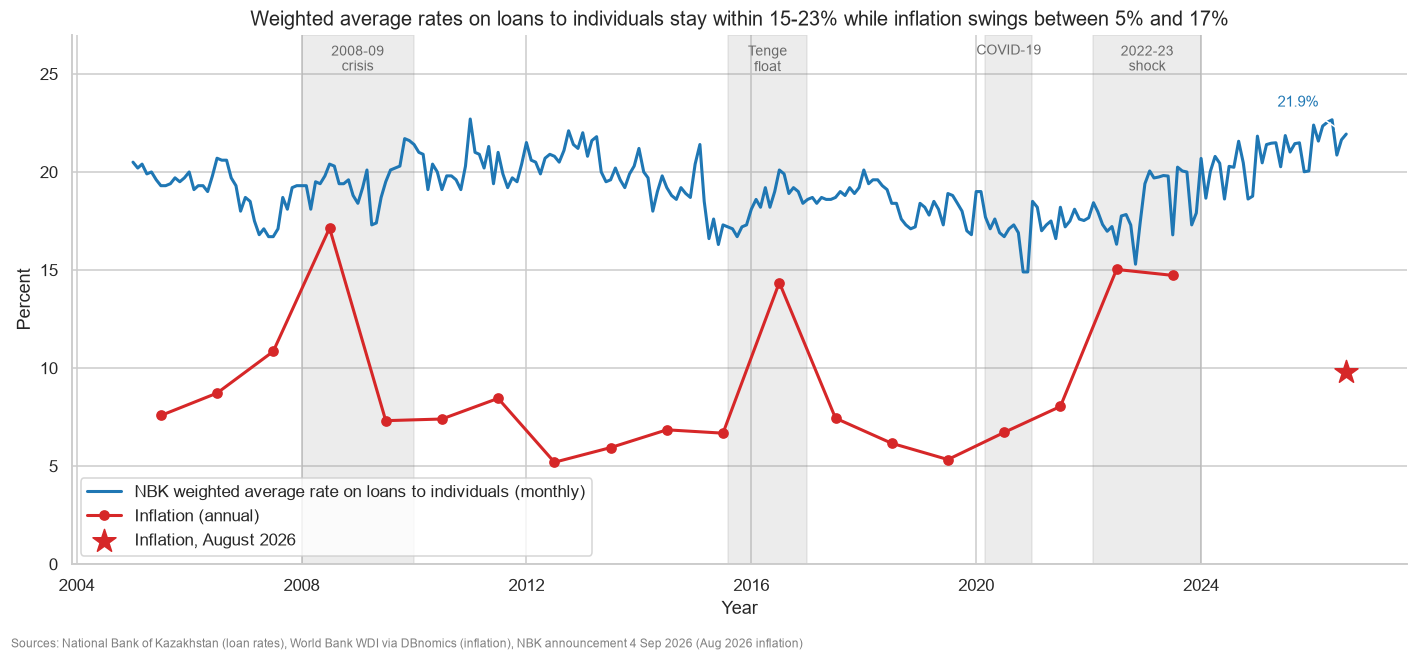

In [95]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    df_nbk["date"],
    df_nbk["loan_rate"],
    color="#1f77b4",
    linewidth=2,
    label="NBK weighted average rate on loans to individuals (monthly)"
)

inflation_dates = pd.to_datetime(df_wb["year"].astype(str) + "-07-01")

ax.plot(
    inflation_dates,
    df_wb["inflation"],
    color="#d62728",
    marker="o",
    linewidth=2,
    label="Inflation (annual)"
)

ax.scatter(
    pd.Timestamp(inflation_now_date + "-01"),
    inflation_now,
    color="#d62728",
    marker="*",
    s=250,
    zorder=5,
    label="Inflation, August 2026"
)

events = [
    ("2008-09\ncrisis", "2008-01-01", "2009-12-31"),
    ("Tenge\nfloat", "2015-08-01", "2016-12-31"),
    ("COVID-19", "2020-03-01", "2020-12-31"),
    ("2022-23\nshock", "2022-02-01", "2023-12-31")
]

ax.set_ylim(0, 27)

for label, start, end in events:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(start, end, color="grey", alpha=0.15)
    ax.text(start + (end - start) / 2, 26.5, label, ha="center", va="top", fontsize=9, color="dimgrey")

last_date = df_nbk["date"].iloc[-1]
last_value = df_nbk["loan_rate"].iloc[-1]

ax.annotate(
    f"{last_value:.1f}%",
    xy=(last_date, last_value),
    xytext=(-45, 18),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    fontsize=10,
    color="#1f77b4"
)

ax.set_title(
    f"Weighted average rates on loans to individuals stay within {df_nbk['loan_rate'].min():.0f}-{df_nbk['loan_rate'].max():.0f}% "
    f"while inflation swings between {df_wb['inflation'].min():.0f}% and {df_wb['inflation'].max():.0f}%",
    fontsize=13
)
ax.set_xlabel("Year")
ax.set_ylabel("Percent")
ax.legend(loc="lower left", frameon=True)

fig.text(0.01, 0.005, "Sources: National Bank of Kazakhstan (loan rates), World Bank WDI via DBnomics (inflation), NBK announcement 4 Sep 2026 (Aug 2026 inflation)", fontsize=8, color="grey")

plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

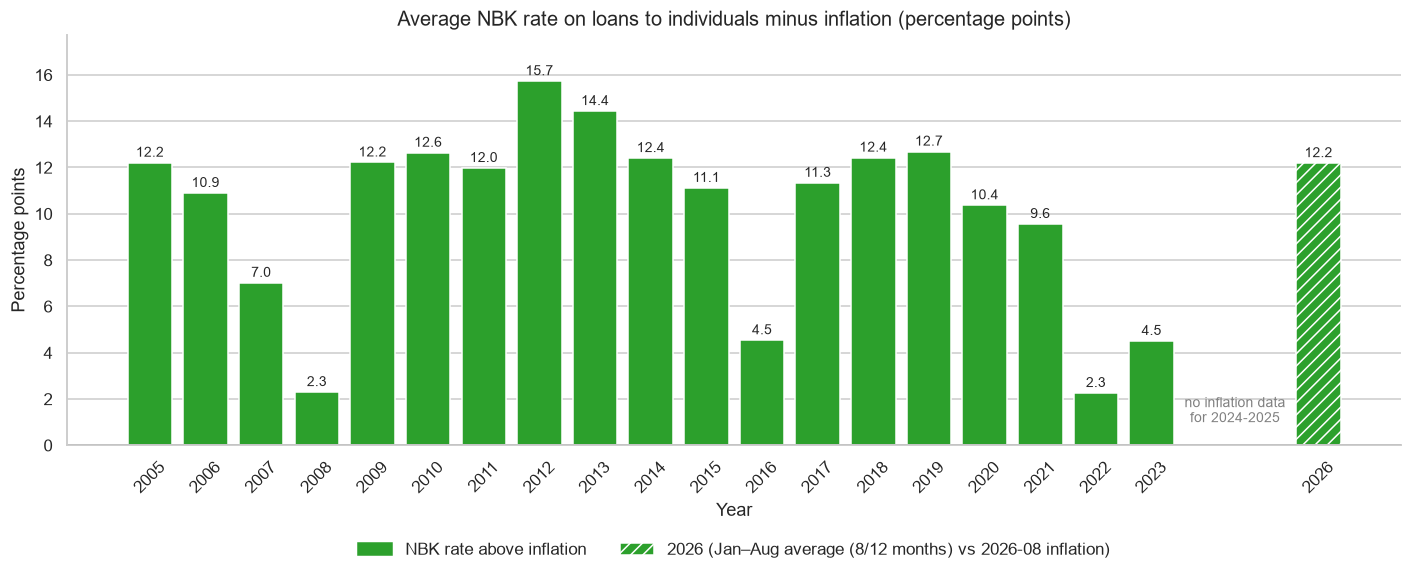

In [96]:
d = df_year.dropna(subset=["rate_minus_inflation"])

loan_2026 = df_nbk_year.loc[df_nbk_year["year"] == 2026, "loan_rate"].iloc[0]
value_2026 = loan_2026 - inflation_now

fig, ax = plt.subplots(figsize=(13, 5.5))

bar_colors = np.where(d["rate_minus_inflation"] >= 0, "#2ca02c", "#d62728")
bars = ax.bar(d["year"], d["rate_minus_inflation"], color=bar_colors)
ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=9)

bar_2026 = ax.bar(
    2026,
    value_2026,
    color="#2ca02c",
    hatch="///",
    edgecolor="white"
)
ax.bar_label(bar_2026, fmt="%.1f", padding=2, fontsize=9)

ax.axhline(0, color="black", linewidth=1)

all_years = list(d["year"]) + [2026]
ax.set_xticks(all_years)
ax.set_xticklabels(all_years, rotation=45)

ax.set_title("Average NBK rate on loans to individuals minus inflation (percentage points)", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Percentage points")
ax.set_ylim(min(0, d["rate_minus_inflation"].min() - 2), max(d["rate_minus_inflation"].max(), value_2026) + 2)
ax.grid(axis="x", visible=False)

ax.text(
    (d["year"].max() + 2026) / 2,
    1,
    f"no inflation data\nfor {d['year'].max() + 1}-2025",
    ha="center",
    fontsize=9,
    color="grey"
)

handles = [
    Patch(color="#2ca02c", label="NBK rate above inflation"),
    Patch(facecolor="#2ca02c", hatch="///", edgecolor="white", label=f"2026 ({coverage_2026} vs {inflation_now_date} inflation)")
]

if (d["rate_minus_inflation"] < 0).any():
    handles.insert(1, Patch(color="#d62728", label="NBK rate below inflation"))

ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)

plt.tight_layout()
plt.show()

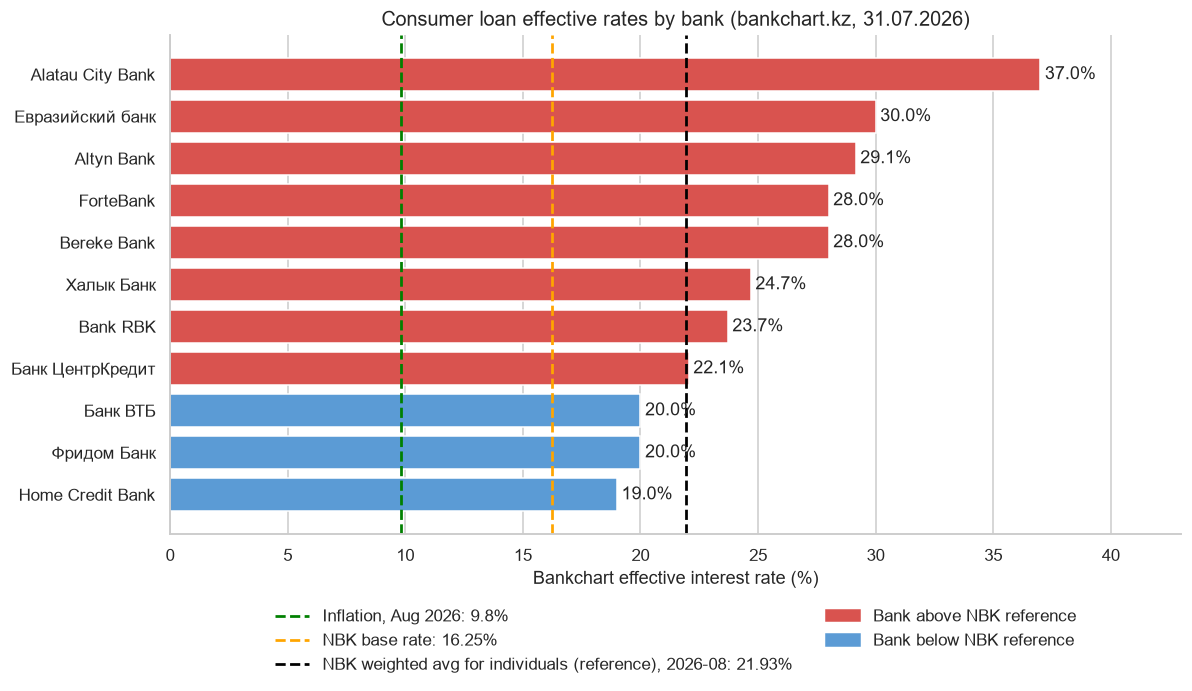

In [97]:
d = df_merged.sort_values("effective_rate")

fig, ax = plt.subplots(figsize=(11, 6.5))

bar_colors = np.where(d["effective_rate"] > market_rate_now, "#d9534f", "#5b9bd5")
bars = ax.barh(d["bank"], d["effective_rate"], color=bar_colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.axvline(inflation_now, color="green", linestyle="--", linewidth=1.8, label=f"Inflation, Aug 2026: {inflation_now}%")
ax.axvline(base_rate, color="orange", linestyle="--", linewidth=1.8, label=f"NBK base rate: {base_rate}%")
ax.axvline(market_rate_now, color="black", linestyle="--", linewidth=1.8, label=f"NBK weighted avg for individuals (reference), {market_rate_date}: {market_rate_now}%")

ax.set_xlim(0, d["effective_rate"].max() + 6)

handles, labels = ax.get_legend_handles_labels()
handles += [
    Patch(color="#d9534f", label="Bank above NBK reference"),
    Patch(color="#5b9bd5", label="Bank below NBK reference")
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)

ax.set_title(f"Consumer loan effective rates by bank (bankchart.kz, {page_date})", fontsize=13)
ax.set_xlabel("Bankchart effective interest rate (%)")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

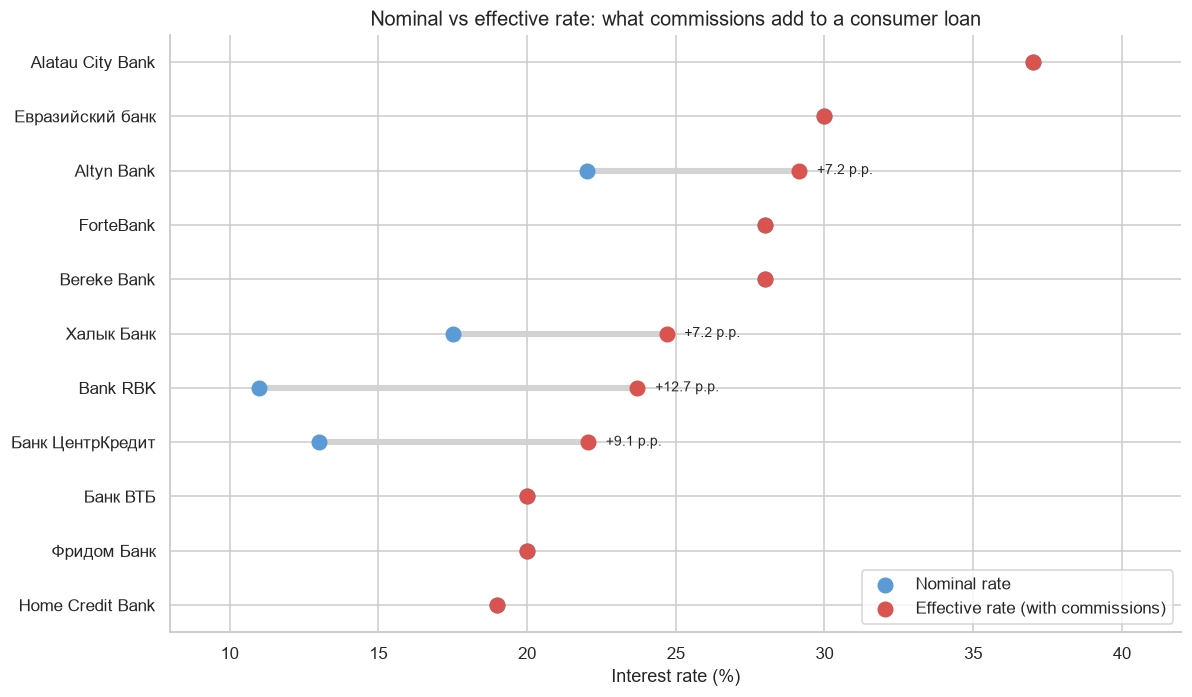

In [98]:
if has_nominal:
    d = df_merged.sort_values("effective_rate").reset_index(drop=True)
    y = np.arange(len(d))

    fig, ax = plt.subplots(figsize=(11, 6.5))

    ax.hlines(y, d["nominal_rate"], d["effective_rate"], color="lightgrey", linewidth=4, zorder=1)
    ax.scatter(d["nominal_rate"], y, color="#5b9bd5", s=90, label="Nominal rate", zorder=2)
    ax.scatter(d["effective_rate"], y, color="#d9534f", s=90, label="Effective rate (with commissions)", zorder=3)

    for i, row in d.iterrows():
        if row["commission_effect"] > 0.5:
            ax.text(
                row["effective_rate"] + 0.6,
                i,
                f"+{row['commission_effect']:.1f} p.p.",
                va="center",
                fontsize=9
            )

    ax.set_yticks(y)
    ax.set_yticklabels(d["bank"])
    ax.set_xlim(8, d["effective_rate"].max() + 5)

    ax.set_title("Nominal vs effective rate: what commissions add to a consumer loan", fontsize=13)
    ax.set_xlabel("Interest rate (%)")
    ax.legend(loc="lower right")

    plt.tight_layout()
    plt.show()
else:
    print("Nominal rates are missing, plot skipped")

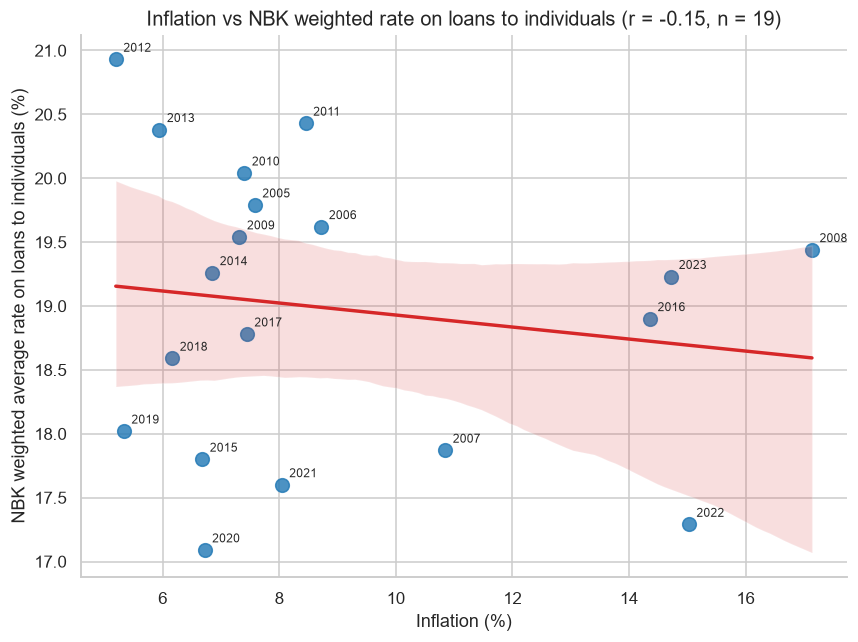

In [99]:
pair = df_year.dropna(subset=["inflation", "loan_rate"])
r_value = pair["inflation"].corr(pair["loan_rate"])

fig, ax = plt.subplots(figsize=(8, 6))

sns.regplot(
    data=pair,
    x="inflation",
    y="loan_rate",
    ax=ax,
    scatter_kws={"s": 80, "color": "#1f77b4"},
    line_kws={"color": "#d62728"}
)

for _, row in pair.iterrows():
    ax.annotate(
        int(row["year"]),
        (row["inflation"], row["loan_rate"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=8
    )

ax.set_title(f"Inflation vs NBK weighted rate on loans to individuals (r = {r_value:.2f}, n = {len(pair)})", fontsize=13)
ax.set_xlabel("Inflation (%)")
ax.set_ylabel("NBK weighted average rate on loans to individuals (%)")

plt.tight_layout()
plt.show()

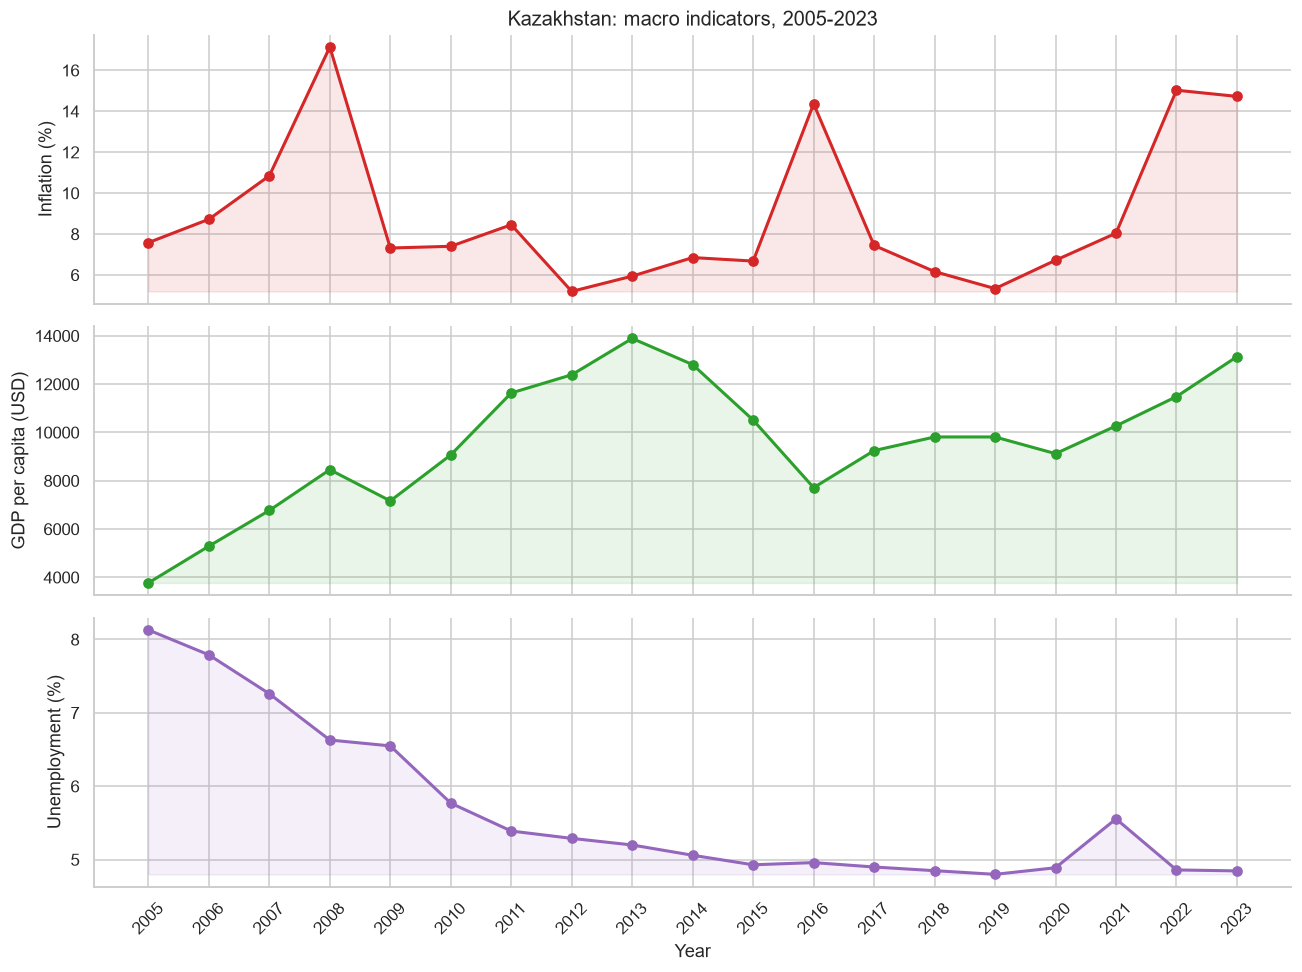

In [100]:
series = [
    ("inflation", "Inflation (%)", "#d62728"),
    ("gdp_per_capita", "GDP per capita (USD)", "#2ca02c"),
    ("unemployment", "Unemployment (%)", "#9467bd")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (col, label, color) in zip(axes, series):
    ax.plot(df_wb["year"], df_wb[col], marker="o", color=color, linewidth=2)
    ax.fill_between(df_wb["year"], df_wb[col], df_wb[col].min(), color=color, alpha=0.1)
    ax.set_ylabel(label)

axes[0].set_title(f"Kazakhstan: macro indicators, {wb_first_year}-{wb_last_year}", fontsize=13)
axes[-1].set_xlabel("Year")
axes[-1].set_xticks(df_wb["year"])
axes[-1].set_xticklabels(df_wb["year"], rotation=45)

plt.tight_layout()
plt.show()

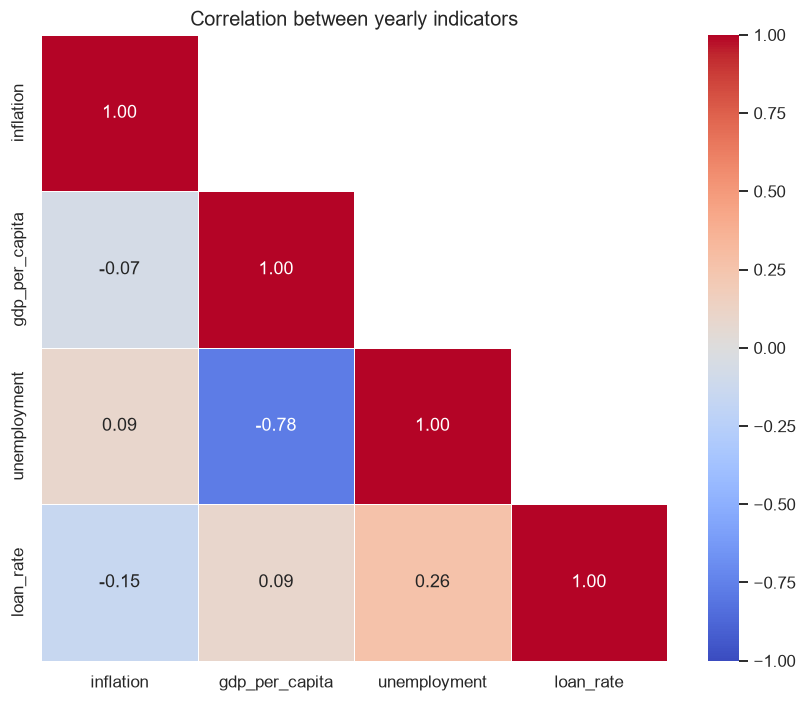

In [101]:
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))

sns.heatmap(
    correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.grid(False)
ax.set_title("Correlation between yearly indicators", fontsize=13)

plt.tight_layout()
plt.show()

In [102]:
print("Rating date on bankchart.kz:", page_date)
print("Banks:", len(df_merged))
print()
print("Effective rate: min", round(df_merged["effective_rate"].min(), 1),
      "| median", round(df_merged["effective_rate"].median(), 1),
      "| mean", round(df_merged["effective_rate"].mean(), 1),
      "| max", round(df_merged["effective_rate"].max(), 1))
print("Inflation (Aug 2026):", inflation_now)
print("NBK base rate:", base_rate)
print("NBK monthly weighted average on loans to individuals,", market_rate_date + ":", market_rate_now)
print()
print("Mean spread over inflation:", round(df_merged["spread_inflation"].mean(), 1), "p.p.")
print("Mean spread over base rate:", round(df_merged["spread_base"].mean(), 1), "p.p.")
print("Mean gap from NBK average (different loan-rate measures):", round(df_merged["spread_market"].mean(), 1), "p.p.")
print("Banks above NBK average (reference only):", int((df_merged["spread_market"] > 0).sum()), "of", len(df_merged))
print("Mean effect of commissions:", round(df_merged["commission_effect"].mean(), 1), "p.p.")
print()
print("Correlation inflation vs loan rate by year:", round(r_value, 2), "(n =", len(pair), ")")
print("NBK weighted rate range", round(df_year["loan_rate"].min(), 1), "-", round(df_year["loan_rate"].max(), 1),
      "| inflation range", round(df_year["inflation"].min(), 1), "-", round(df_year["inflation"].max(), 1))
print(f"NBK rate, 2025 -> 2026 ({coverage_2026}):",
      round(df_nbk_year.loc[df_nbk_year["year"] == 2025, "loan_rate"].iloc[0], 1), "->", round(loan_2026, 1))

Rating date on bankchart.kz: 31.07.2026
Banks: 11

Effective rate: min 19.0 | median 24.7 | mean 25.6 | max 37.0
Inflation (Aug 2026): 9.8
NBK base rate: 16.25
NBK monthly weighted average on loans to individuals, 2026-08: 21.93

Mean spread over inflation: 15.8 p.p.
Mean spread over base rate: 9.4 p.p.
Mean gap from NBK average (different loan-rate measures): 3.7 p.p.
Banks above NBK average (reference only): 8 of 11
Mean effect of commissions: 3.3 p.p.

Correlation inflation vs loan rate by year: -0.15 (n = 19 )
NBK weighted rate range 17.1 - 22.0 | inflation range 5.2 - 17.1
NBK rate, 2025 -> 2026 (Jan–Aug average (8/12 months)): 21.1 -> 22.0
